In [94]:
from legendmeta import LegendMetadata
from dbetto import Props, TextDB
from datetime import datetime
import json
import yaml
import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from matplotlib.colors import ListedColormap, BoundaryNorm
from collections.abc import Mapping



In [2]:
#We will start by importing and constructing the (LegendMetadata)
#[https://pylegendmeta.readthedocs.io/en/stable/api/legendmeta.html#legendmeta.core.LegendMetadata] object. If no argument is provided, the most recent version of legend-metadata will be fetched from github. 
#Instead, we will grab the version that was used for the nu24 analysis

In [3]:
# Pretty print nested dict/list structures
def pprint(val, nlines=None):
    # Don't think too hard about this...If it bothers you, go to the Juleana tutorial instead
    if nlines is not None:
        print('\n'.join(yaml.safe_dump(json.loads(json.dumps(val, sort_keys=False)), sort_keys=False).split('\n')[:nlines]))
        print('...')
    else:
        print(yaml.safe_dump(json.loads(json.dumps(val, sort_keys=False)), sort_keys=False))

In [4]:
l200_data_dir = "/dvs_ro/cfs/cdirs/m2676/data/lngs/l200/public/prodenv/prod-blind/ref/v2.1.5"
config = Props.read_from(f"{l200_data_dir}/config.json", subst_pathvar=True)["setups"]["l200"]["paths"]
meta = LegendMetadata(config["metadata"])

In [5]:
# clona la versione più recente da github
meta = LegendMetadata()

Cloning git@github.com:legend-exp/legend-metadata in /tmp/legend-metadata-ritaferi...
Checking out the latest stable tag (v1.5.5)...


In [69]:
meta.hardware.detectors.germanium.diodes.V05612B.characterization.l200_site.fccd_in_mm.am241.uncertainty

{'uncorr': {'pos': 0.0126011197100119, 'neg': 0.0124794218566661},
 'corr': {'pos': 0.0331121393515334, 'neg': 0.0339830012047451}}

array(dict_keys(['V14673A', 'V14654A', 'V13049A', 'V13046A', 'V13044A', 'V06659A', 'V06649M', 'V06649A', 'V05261B', 'V05261A', 'V01240A', 'V01239A', 'P00909A', 'B00091D', 'B00091C', 'B00091B', 'B00091A', 'B00089D', 'B00089C', 'B00089B', 'B00089A', 'B00079C', 'B00079B', 'B00076C', 'B00076B', 'B00061C', 'B00061B', 'B00061A', 'B00035C', 'B00035B', 'B00035A', 'B00032D', 'B00032C', 'B00032B', 'B00032A', 'B00002C', 'B00002B', 'B00002A', 'B00000D', 'B00000C', 'B00000B', 'B00000A', 'V14618A', 'V11947B', 'V11925A', 'V11924A', 'V10784A', 'V10447B', 'V10437B', 'V09724A', 'V09374A', 'V09372A', 'V08682B', 'V08682A', 'V07647B', 'V07647A', 'V07646A', 'V07302B', 'V07302A', 'V07298B', 'V06643A', 'V05612B', 'V05612A', 'V05268B', 'V05268A', 'V05267B', 'V05267A', 'V05266B', 'V05266A', 'V04549B', 'V04549A', 'V04545A', 'V04199A', 'V03422A', 'V03421A', 'V02166B', 'V02162B', 'V02160B', 'V02160A', 'V01415A', 'V01406A', 'V01404A', 'V01403A', 'V01389A', 'V01387A', 'V01386A', 'V00074A', 'V00050B', 'V00050A', 'V00

In [12]:
config;



In [7]:
#pars_pht = TextDB(f"{config['par_pht']}");



In [8]:
meta.keys()

dict_keys(['datasets', 'simprod', 'jldataprod', 'hardware', 'dataprod'])

In [9]:
from pathlib import Path
from itertools import combinations
import pandas as pd

base = Path(
    "/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref"
)
from pathlib import Path

base = Path(
    "/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref"
)
versions = ["v1.0.0", "v1.1.0", "v1.2.1", "v1.2.2"]

# Detector HADES per versione
hades_by_version = {}

for version in versions:
    hit_dir = base / version / "generated/tier/hit"

    if hit_dir.is_dir():
        hades_by_version[version] = {
            p.name for p in hit_dir.iterdir() if p.is_dir()
        }

# Unione dei detector di tutte le versioni HADES
hades_detectors = set().union(*hades_by_version.values())

# Detector presenti nei metadati LEGEND
legend_detectors = set(meta.channelmap().keys())

# Detector comuni
common_detectors = sorted(hades_detectors & legend_detectors)

print(f"Detector HADES: {len(hades_detectors)}")
print(f"Detector nei metadati LEGEND: {len(legend_detectors)}")
print(f"Detector comuni: {len(common_detectors)}")
print(*common_detectors, sep="\n")

Detector HADES: 26
Detector nei metadati LEGEND: 199
Detector comuni: 24
V03421A
V03422A
V04199A
V04545A
V06643A
V06659A
V07298B
V07302A
V07302B
V07647B
V08682A
V08682B
V09372A
V10437B
V10447B
V10784A
V11924A
V11925A
V11947B
V13044A
V13049A
V14618A
V14654A
V14673A


In [10]:


# Unione dei detector di tutte le versioni HADES
hades_detectors = set().union(*hades_by_version.values())

# Detector presenti nei metadati LEGEND
legend_detectors = set(meta.channelmap().keys())

# Detector comuni
common_detectors = sorted(hades_detectors & legend_detectors)

print(f"Detector HADES: {len(hades_detectors)}")


print(f"Detector nei metadati LEGEND: {len(legend_detectors)}")
print(f"Detector comuni: {len(common_detectors)}")
print(*common_detectors, sep="\n")

Detector HADES: 26
Detector nei metadati LEGEND: 199
Detector comuni: 24
V03421A
V03422A
V04199A
V04545A
V06643A
V06659A
V07298B
V07302A
V07302B
V07647B
V08682A
V08682B
V09372A
V10437B
V10447B
V10784A
V11924A
V11925A
V11947B
V13044A
V13049A
V14618A
V14654A
V14673A


In [11]:
 #legend_detectors = set(meta.channelmap().keys())

for version, hades_detectors in hades_by_version.items():
    common = sorted(hades_detectors & legend_detectors)

    print(f"\n{version}: {len(common)}")
    print(*common, sep="\n")


v1.1.0: 8
V03421A
V03422A
V04199A
V04545A
V08682A
V08682B
V09372A
V14673A

v1.2.1: 19
V03421A
V03422A
V06643A
V06659A
V07298B
V07302A
V07302B
V07647B
V10437B
V10447B
V10784A
V11924A
V11925A
V11947B
V13044A
V13049A
V14618A
V14654A
V14673A


# risoluzione

In [45]:
import glob
import yaml

detector = "V14618A"

pattern = (
    "/global/cfs/cdirs/m2676/data/teststands/hades/"
    "prodenv/ref/v1.2.1/generated/par/hit/"
    f"{detector}/c1/am_HS1_lat_dlt/*.yaml"
)

files_par = sorted(glob.glob(pattern))

if not files_par:
    raise FileNotFoundError(f"Nessun file trovato: {pattern}")

print(f"File trovati: {len(files_par)}")

# Carica tutti i YAML: una voce per ogni file.
parameters_by_file = {}

for filename in files_par:
    with open(filename, encoding="utf-8") as stream:
        parameters_by_file[filename] = yaml.safe_load(stream)

    print(filename)



File trovati: 1
/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/par/hit/V14618A/c1/am_HS1_lat_dlt/char_data-V14618A-am_HS1_lat_dlt-r001-20250604T105822Z-par_hit.yaml


In [46]:
# Dizionario del primo file.

par = parameters_by_file[files_par[0]]
print(par.keys())

dict_keys(['pars', 'results'])


In [47]:
par['results']['ecal']['cuspEmax_ctc_cal']["eres_linear"]

{'function': 'FWHMLinear',
 'module': 'pygama.pargen.energy_cal',
 'expression': '(a+b*x)**(0.5)',
 'parameters': {'a': 0.5399831562577209, 'b': 0.0011019267803187864},
 'uncertainties': {'a': 0.06955380271392347, 'b': 0.0011686814093988661},
 'cov': [[0.0048449521017629995, -8.120960646943744e-05],
  [-8.120960646943744e-05, 1.3666608833650732e-06]],
 'csqr': [2.2965096069109294e-08, -1],
 'p_val': nan}

In [48]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(10,3000,3000)
a = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["a"]

b = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["b"]

c = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["c"]


fwhm_q = (a+b*x+c*x**2)**(0.5)

In [49]:
a = par['results']['ecal']['cuspEmax_ctc_cal']["eres_linear"]["parameters"]["a"]

b = par['results']['ecal']['cuspEmax_ctc_cal']["eres_linear"]["parameters"]["b"]


fwhm_l = (a+b*x)**(0.5)

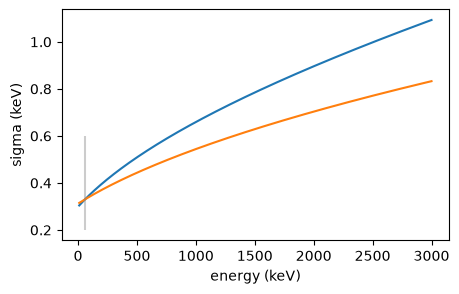

In [53]:
plt.figure(figsize = (5,3))
plt.plot(x, fwhm_q / 2.355)
plt.plot(x, fwhm_l / 2.355)
plt.ylabel('sigma (keV)' )
plt.xlabel('energy (keV)' )
plt.vlines(60, 0.2, 0.6, color = 'grey', alpha = 0.4,)

# check misure mancanti/presenti

In [75]:

detectors = legend_detectors

In [90]:
detectors = np.array(
    sorted(meta.hardware.detectors.germanium.diodes.keys()),
    dtype=str,
)

In [114]:
detectors = ["V03421A",
"V03422A",
"V06643A",
"V06659A",
"V07298B",
"V07302A",
"V07302B",
"V07647B",
"V10437B",
"V10447B",
"V10784A",
"V11924A",
"V11925A",
"V11947B",
"V13044A",
"V13049A",
"V14618A",
"V14654A",
"V14673A",
]


In [120]:
# ============================================================
# CONFIGURATION
# ============================================================

max_detectors_per_table = 15

groups = [
    ("V", "V detectors", "deepskyblue"),
    ("B", "B detectors", "darkorange"),
    ("C", "C detectors", "mediumseagreen"),
    ("P", "P detectors", "mediumpurple"),
]

measurement_names = sorted(all_measurement_names)
n_measurements = len(measurement_names)

if max_detectors_per_table < 1:
    raise ValueError("max_detectors_per_table must be positive.")

detectors_by_group = {
    prefix: sorted(
        name for name in detector_names
        if name.startswith(prefix)
    )
    for prefix, _, _ in groups
}

tables_by_group = {
    prefix: [
        names[start:start + max_detectors_per_table]
        for start in range(0, len(names), max_detectors_per_table)
    ]
    for prefix, names in detectors_by_group.items()
}


# ============================================================
# FIGURE
# ============================================================

if not measurement_names:
    print("No FCCD measurement entries found.")

elif not any(detectors_by_group.values()):
    print("No detectors found.")

else:
    # Ogni tabella comprende una colonna per i nomi
    # e una colonna per ciascuna misura.
    label_width = 1.7
    cell_width = 1.5
    table_gap = 0.5

    table_width = label_width + n_measurements * cell_width
    table_stride = table_width + table_gap

    panel_widths = [
        max(1, len(tables_by_group[prefix])) * table_stride
        for prefix, _, _ in groups
    ]

    max_rows = max(
        len(table)
        for tables in tables_by_group.values()
        for table in tables
    )

    fig, axes = plt.subplots(
        1,
        4,
        figsize=(
            max(7, sum(panel_widths)),
            max(3, 0.4 * max_rows + 2),
        ),
        gridspec_kw={"width_ratios": panel_widths},
        layout="constrained",
        dpi=400,
    )

    for ax, (prefix, title, color) in zip(axes, groups):
        tables = tables_by_group[prefix]

        ax.set_title(
            f"{title} — {len(detectors_by_group[prefix])} detectors",
            fontsize=11,
            pad=12,
        )

        if not tables:
            ax.text(
                0.5, 0.5,
                "No detectors available",
                transform=ax.transAxes,
                ha="center",
                va="center",
            )
            ax.set_axis_off()
            continue

        cmap = ListedColormap(["lightgray", color])
        norm = BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

        for table_index, names in enumerate(tables):
            offset = table_index * table_stride
            cells_left = offset + label_width

            presence = np.array([
                [
                    int(
                        measurement
                        in measurements_by_detector.get(detector, {})
                    )
                    for measurement in measurement_names
                ]
                for detector in names
            ])

            x_edges = (
                cells_left
                + np.arange(n_measurements + 1) * cell_width
            )
            y_edges = np.arange(len(names) + 1)

            ax.pcolormesh(
                x_edges,
                y_edges,
                presence,
                cmap=cmap,
                norm=norm,
                edgecolors="white",
                linewidth=1,
                shading="flat",
            )

            # Intestazione delle misure per ogni tabella.
            for column, measurement_name in enumerate(measurement_names):
                ax.text(
                    cells_left + (column + 0.5) * cell_width,
                    -0.3,
                    measurement_name,
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    rotation=30,
                )

            # Nomi detector e valori.
            for row, detector in enumerate(names):
                available = measurements_by_detector.get(detector, {})

                ax.text(
                    cells_left - 0.08,
                    row + 0.5,
                    f"{detector} (N={len(available)})",
                    ha="right",
                    va="center",
                    fontsize=7,
                )

                for column, measurement_name in enumerate(measurement_names):
                    measurement = available.get(measurement_name)

                    ax.text(
                        cells_left + (column + 0.5) * cell_width,
                        row + 0.5,
                        format_measurement(measurement)
                        if measurement is not None else "–",
                        ha="center",
                        va="center",
                        fontsize=7,
                        color=(
                            "black"
                            if measurement is not None
                            else "dimgray"
                        ),
                    )

        ax.set_xlim(
            0,
            len(tables) * table_stride - table_gap,
        )
        ax.set_ylim(max_rows + 0.1, -1.3)
        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

    handles = [
        Patch(facecolor=color, label=f"{prefix} — available")
        for prefix, _, color in groups
    ]
    handles.append(
        Patch(facecolor="lightgray", label="Missing")
    )

    fig.legend(
        handles=handles,
        loc="outside lower center",
        ncol=5,
        frameon=False,
        fontsize=9,
    )

    fig.suptitle(
        "FCCD measurements and uncertainties (mm)",
        fontsize=13,
    )


    plt.savefig('plot.png')